In [1]:
import sys
import os
sys.path.insert(1, '/home/sonndt/Projects/FFV_PINN')
import copy
import itertools
import os
import jax
import jax.numpy as jnp
import matplotlib.pyplot as plt

from jaxpi.samplers import UniformSampler
from nc_porous.config import base_line_ffv  # File config chuẩn của bạn
from nc_porous.models import PorousNaturalConvection2D
from nc_porous.train import train_porous

E0915 17:37:41.479388   15724 cuda_executor.cc:1182] [0] Failed to allocate device memory of 5.78GiB (6209667072 bytes): RESOURCE_EXHAUSTED: : CUDA_ERROR_OUT_OF_MEMORY: out of memory
E0915 17:37:41.479458   15724 cuda_executor.cc:1182] [0] Failed to allocate device memory of 5.20GiB (5588700160 bytes): RESOURCE_EXHAUSTED: : CUDA_ERROR_OUT_OF_MEMORY: out of memory
E0915 17:37:41.479510   15724 cuda_executor.cc:1182] [0] Failed to allocate device memory of 4.68GiB (5029830144 bytes): RESOURCE_EXHAUSTED: : CUDA_ERROR_OUT_OF_MEMORY: out of memory
E0915 17:37:41.479560   15724 cuda_executor.cc:1182] [0] Failed to allocate device memory of 4.22GiB (4526846976 bytes): RESOURCE_EXHAUSTED: : CUDA_ERROR_OUT_OF_MEMORY: out of memory
E0915 17:37:41.479610   15724 cuda_executor.cc:1182] [0] Failed to allocate device memory of 3.79GiB (4074162176 bytes): RESOURCE_EXHAUSTED: : CUDA_ERROR_OUT_OF_MEMORY: out of memory
E0915 17:37:41.479657   15724 cuda_executor.cc:1182] [0] Failed to allocate device me

In [2]:
def create_batches(config):
  H, L = config.physics.H, config.physics.L
  domain = jnp.array([[0.0, L], [0.0, H]])
  scheme = config.diff.scheme

  if scheme in ["nd", "can"]: 
    sampler = MeshSampler(domain, config.training.batch_size)
    n_x = config.diff.n_x 
    n_y = config.diff.n_y 
    dx = L / (n_x - 1)
    dy = L / (n_y - 1)
    safe_x = dx if scheme == "can" else 2.0 * dx 
    safe_y = dy if scheme == "can" else 2.0 * dy

    x_inner = jnp.linspace(safe_x, L - safe_x, n_x - 2)
    y_inner = jnp.linspace(safe_y, H - safe_y, n_y - 2)
    X, Y = jnp.meshgrid(x_inner, y_inner, indexing="ij")
    mesh_points = jnp.column_stack([X.ravel(), Y.ravel()])

    config.diff.h_stencil = float(dx)
    sampler = MeshSampler(mesh=mesh_points, batch_size=config.training.batch_size)
    
  elif scheme == "ad":
    sampler = UniformSampler(domain, config.training.batch_size)

  if config.training.random_sampling:
    return sampler
  return itertools.repeat(next(iter(sampler)))

In [4]:
def run_ablation_experiment(exp_name, modify_config_fn=None):
    # Sao chép cấu hình gốc
    sub_config = copy.deepcopy(base_line_ffv.get_config())
    sub_config.wandb.name = f"{sub_config.wandb.name}_{exp_name}"

    # Áp dụng các thay đổi tham số riêng cho từng case thử nghiệm
    if modify_config_fn is not None:
        sub_config = modify_config_fn(sub_config)

    # Tạo luồng dữ liệu batch (shape: (batch_size, 2))
    batches = create_batches(sub_config)

    # Tiến hành huấn luyện
    model, history = train_porous(config=sub_config, samplers=batches)
    return model, history

In [ ]:
# Case 1: Mô hình đề xuất (Bật Adaptive Pseudo-Time Stepping)
import gc
from jaxpi.samplers import MeshSampler

def cfg_pts_on(cfg):
    cfg.pseudo_time.enabled = True
    cfg.pseudo_time.strategy = "dynamic"
    return cfg

def cfg_pts_off(cfg):
    cfg.pseudo_time.enabled = False
    return cfg

def wrapper_cfg(ra_val, pts_enabled, diff_scheme):    
    def modify_config(cfg):
        cfg.physics.Ra = ra_val
        cfg.pseudo_time.enabled = pts_enabled
        cfg.diff.scheme = diff_scheme
        return cfg
    return modify_config

_ra = [1e2, 1e3, 1e4, 1e5, 1e6]
_pts = [True, False]  
_diff_schemes = ["ad", "can"]

for ra_val in _ra:
    for pts_enabled in _pts:
        for diff_scheme in _diff_schemes:
            exp_name = f"ra_{ra_val}_pts_{'on' if pts_enabled else 'off'}_diff_{diff_scheme}"
            modify_fn = wrapper_cfg(ra_val, pts_enabled, diff_scheme)
            print(f"Running experiment: {exp_name} with Ra={ra_val}, PTS={'on' if pts_enabled else 'off'}, Diff={diff_scheme}")
            model, hist = run_ablation_experiment(exp_name, modify_config_fn=modify_fn)
            del model, hist 
            gc.collect() 
            jax.clear_cache()

# for ra_val in _ra:
#     for pts_enabled in _pts:
#         exp_name = f"ra_{ra_val}_pts_{'on' if pts_enabled else 'off'}"
#         modify_fn = wrapper_cfg(ra_val, pts_enabled)
#         print(f"Running experiment: {exp_name} with Ra={ra_val} and PTS={'on' if pts_enabled else 'off'}")
#         model, hist = run_ablation_experiment(exp_name, modify_config_fn=modify_fn)
#         del model, hist 
#         gc.collect() 
#         jax.clear_cache()

print("All experiments completed.")

Training PINN:   0%|          | 0/50000 [00:00<?, ?it/s]

Bắt đầu huấn luyện...
Step 00500 | Loss: 5.0130e-02 | T_dirichlet_bc: 2.083e-04 | T_neumann_bc: 2.487e-04 | T_res: 4.703e-03 | p_res: 1.364e-02 | u_bc: 5.916e-04 | u_res: 9.784e-03 | v_bc: 3.397e-04 | v_res: 1.021e-02 | tau_T: 7.44 | tau_p: 4.07 | tau_u: 10.90 | tau_v: 10.90 | Time/Log: 95.22s
Step 01000 | Loss: 1.1338e-01 | T_dirichlet_bc: 1.549e-04 | T_neumann_bc: 2.540e-04 | T_res: 5.019e-03 | p_res: 4.953e-02 | u_bc: 1.625e-03 | u_res: 1.580e-02 | v_bc: 1.196e-03 | v_res: 1.009e-02 | tau_T: 7.44 | tau_p: 4.07 | tau_u: 10.90 | tau_v: 10.90 | Time/Log: 9.10s
Step 01500 | Loss: 5.5029e-02 | T_dirichlet_bc: 3.888e-04 | T_neumann_bc: 3.424e-05 | T_res: 6.087e-03 | p_res: 7.608e-03 | u_bc: 1.756e-03 | u_res: 7.299e-03 | v_bc: 6.134e-04 | v_res: 5.590e-03 | tau_T: 8.05 | tau_p: 4.29 | tau_u: 11.18 | tau_v: 10.67 | Time/Log: 19.09s
Step 02000 | Loss: 6.4523e-02 | T_dirichlet_bc: 3.701e-04 | T_neumann_bc: 5.804e-05 | T_res: 5.235e-03 | p_res: 9.290e-03 | u_bc: 1.400e-03 | u_res: 6.646e-03 |

In [6]:
import os
import pickle
import jaxpi

from jaxpi.checkpointing import create_checkpoint_manager, restore_checkpoint
from jaxpi.models import (
    create_arch,
    create_lr_schedule,
    create_optimizer,
    create_train_state,
)
from nc_porous.config import base_line_ffv
from nc_porous.models import PorousNaturalConvection2D


def load_saved_model(exp_name, step=None):
  """Nạp mô hình và history từ thư mục outputs.

  Args:
      exp_name: Tên thí nghiệm (ví dụ: 'With_PTS_Adaptive')
      step: Bước lặp cần load (int). Nếu None, tự động load bước mới nhất.
  """
  # 1. Tái tạo cấu hình khớp với thí nghiệm đã chạy
  config = base_line_ffv.get_config()
  config.wandb.name = f"{config.wandb.name}_{exp_name}"

  # 2. Khởi tạo train state rỗng theo cấu trúc mạng
  lr = create_lr_schedule(config.optim)
  tx = create_optimizer(config.optim, lr)
  arch = create_arch(config.arch)
  state = create_train_state(config, tx, arch)

  # 3. Khởi tạo đối tượng model
  model = PorousNaturalConvection2D(config, lr, tx, arch, state)

  # 4. Xác định đường dẫn checkpoint và nạp trọng số
  ckpt_dir = os.path.join(os.getcwd(), "outputs", config.wandb.name, "ckpt")
  ckpt_mngr = create_checkpoint_manager(config.saving, ckpt_dir)

  target_step = step if step is not None else ckpt_mngr.latest_step()
  if target_step is None:
    raise FileNotFoundError(
        f"Không tìm thấy checkpoint nào trong thư mục: {ckpt_dir}"
    )

  # Gán đè state đã phục hồi vào model
  model.state = restore_checkpoint(ckpt_mngr, model.state, step=target_step)
  print(f"-> Đã nạp thành công checkpoint tại step {int(model.state.step)}")

  # 5. Đọc lại file history.pkl (nếu có)
  history_path = os.path.join(
      os.getcwd(), "outputs", config.wandb.name, "history.pkl"
  )
  history = {}
  if os.path.exists(history_path):
    with open(history_path, "rb") as f:
      history = pickle.load(f)
    print(f"-> Đã nạp lịch sử huấn luyện: {len(history.get('loss', []))} bước log")

  return model, history, config

In [9]:
# Tải lại mô hình đã huấn luyện
model_nd, hist_nd, _ = load_saved_model("ra_1e6_pts_on_diff_can_201x201")
model_can, hist_can, _ = load_saved_model("ra_1e6_pts_on_diff_can")
model_ad, hist_ad, _ = load_saved_model("ra_1e6_pts_on_diff_ad")

-> Đã nạp thành công checkpoint tại step 50000
-> Đã nạp lịch sử huấn luyện: 500 bước log
-> Đã nạp thành công checkpoint tại step 50000
-> Đã nạp lịch sử huấn luyện: 500 bước log
-> Đã nạp thành công checkpoint tại step 50000
-> Đã nạp lịch sử huấn luyện: 500 bước log


<>:60: SyntaxWarning: "\m" is an invalid escape sequence. Such sequences will not work in the future. Did you mean "\\m"? A raw string is also an option.
<>:72: SyntaxWarning: "\m" is an invalid escape sequence. Such sequences will not work in the future. Did you mean "\\m"? A raw string is also an option.
<>:84: SyntaxWarning: "\m" is an invalid escape sequence. Such sequences will not work in the future. Did you mean "\\m"? A raw string is also an option.
<>:60: SyntaxWarning: "\m" is an invalid escape sequence. Such sequences will not work in the future. Did you mean "\\m"? A raw string is also an option.
<>:72: SyntaxWarning: "\m" is an invalid escape sequence. Such sequences will not work in the future. Did you mean "\\m"? A raw string is also an option.
<>:84: SyntaxWarning: "\m" is an invalid escape sequence. Such sequences will not work in the future. Did you mean "\\m"? A raw string is also an option.
/tmp/ipykernel_65489/3744075518.py:60: SyntaxWarning: "\m" is an invalid esc

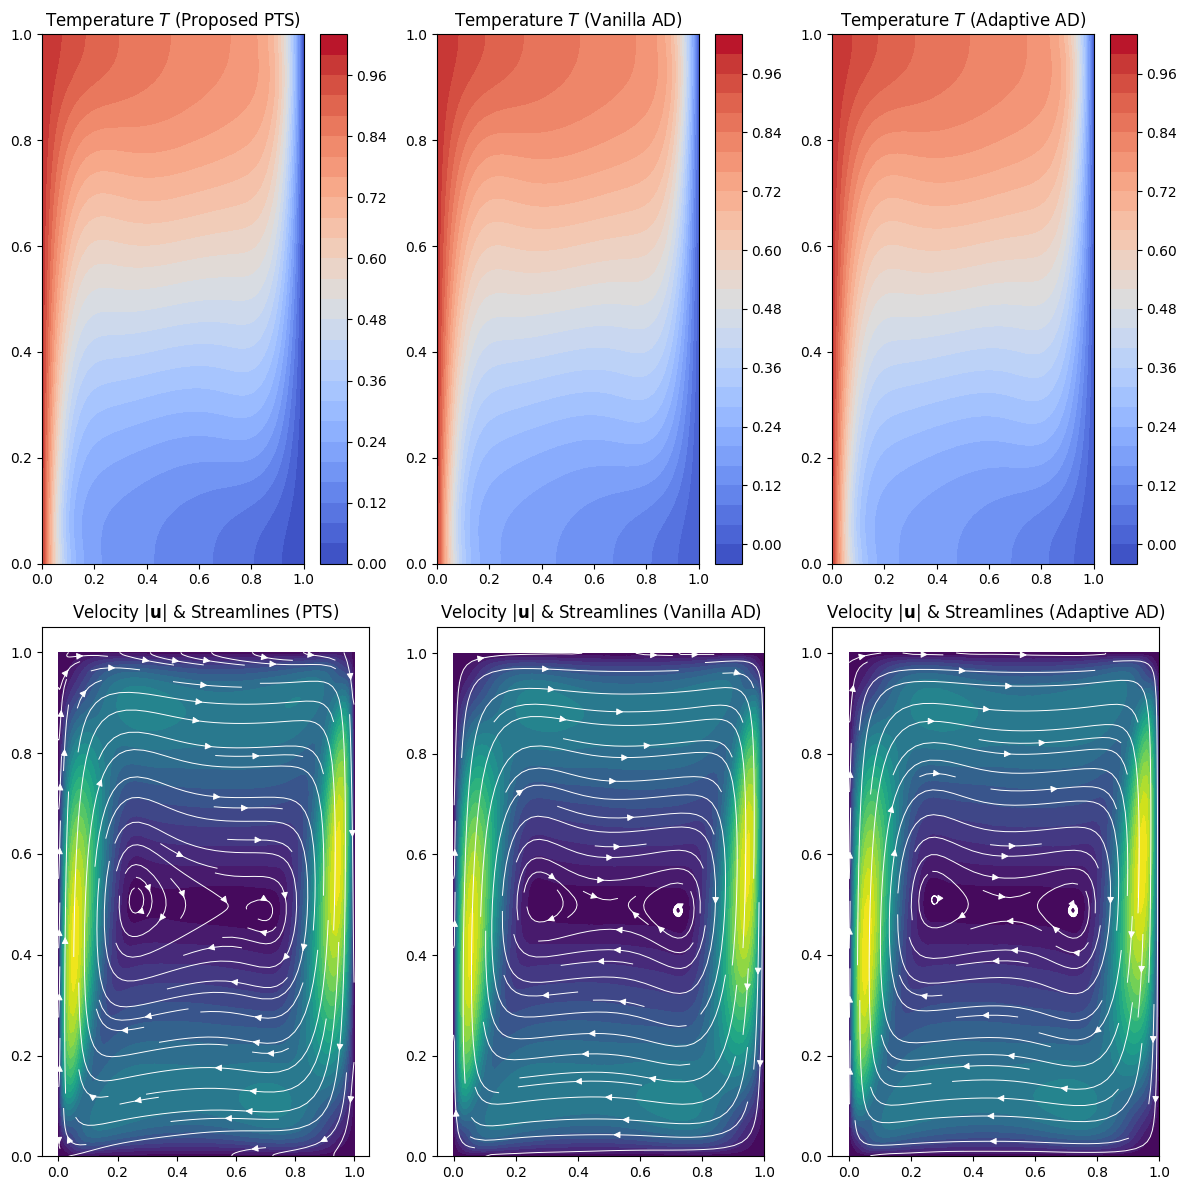

In [ ]:
import jax
import jax.numpy as jnp

# Tạo lưới đều 100x100 để nội suy trường nghiệm
Nx, Ny = 100, 100
x_lin = jnp.linspace(0.0, 1.0, Nx)
y_lin = jnp.linspace(0.0, 1.0, Ny)
X, Y = jnp.meshgrid(x_lin, y_lin)
x_flat, y_flat = X.ravel(), Y.ravel()
import numpy as np

def evaluate_fields(model):
  u, v, p, T = jax.vmap(model.neural_net, (None, 0, 0))(
      model.state.params, x_flat, y_flat
  )
  return (
      np.array(u).reshape(Ny, Nx),
      np.array(v).reshape(Ny, Nx),
      np.array(p).reshape(Ny, Nx),
      np.array(T).reshape(Ny, Nx),
  )


u_nd, v_nd, _, T_nd = evaluate_fields(model_nd)
u_can, v_can, _, T_can = evaluate_fields(model_can)
u_ad, v_ad, _, T_ad = evaluate_fields(model_ad)

# Vẽ so sánh 3 mô hình
#fig, axs = plt.subplots(2, 2, figsize=(12, 10))
fig, axs = plt.subplots(2, 3, figsize=(12, 12))

# Đường đẳng nhiệt T (Isotherms)
im1 = axs[0, 0].contourf(X, Y, T_nd, levels=25, cmap='coolwarm')
axs[0, 0].set_title('Temperature $T$ (Proposed PTS)')
plt.colorbar(im1, ax=axs[0, 0])

im2 = axs[0, 1].contourf(X, Y, T_can, levels=25, cmap='coolwarm')
axs[0, 1].set_title('Temperature $T$ (Vanilla AD)')
plt.colorbar(im2, ax=axs[0, 1])

im3 = axs[0, 2].contourf(X, Y, T_ad, levels=25, cmap='coolwarm')
axs[0, 2].set_title('Temperature $T$ (Adaptive AD)')
plt.colorbar(im3, ax=axs[0, 2])

# Độ lớn vận tốc & Đường dòng (Velocity Magnitude & Streamlines)
vel_mag_nd = np.sqrt(u_nd**2 + v_nd**2)
vel_mag_can = np.sqrt(u_can**2 + v_can**2)
vel_mag_ad = np.sqrt(u_ad**2 + v_ad**2)

axs[1, 0].contourf(X, Y, vel_mag_nd, levels=25, cmap='viridis')
axs[1, 0].streamplot(
    np.array(x_lin),
    np.array(y_lin),
    u_nd,
    v_nd,
    color='white',
    density=1.0,
    linewidth=0.7,
)
axs[1, 0].set_title('Velocity $|\mathbf{u}|$ & Streamlines (PTS)')

axs[1, 1].contourf(X, Y, vel_mag_can, levels=25, cmap='viridis')
axs[1, 1].streamplot(
    np.array(x_lin),
    np.array(y_lin),
    u_can,
    v_can,
    color='white',
    density=1.0,
    linewidth=0.7,
)
axs[1, 1].set_title('Velocity $|\mathbf{u}|$ & Streamlines (Vanilla AD)')

axs[1, 2].contourf(X, Y, vel_mag_ad, levels=25, cmap='viridis')
axs[1, 2].streamplot(
    np.array(x_lin),
    np.array(y_lin),
    u_ad,
    v_ad,
    color='white',
    density=1.0,
    linewidth=0.7,
)
axs[1, 2].set_title('Velocity $|\mathbf{u}|$ & Streamlines (Adaptive AD)')

plt.tight_layout()
plt.show()

In [21]:
import jax


import jax
import jax.numpy as jnp

import jax
import jax.numpy as jnp

def compute_benchmark_metrics(model, Nx=201, Ny=201):
    """
    Tính toán đầy đủ các thông số chuẩn (Benchmark Metrics) đối lưu tự nhiên:
    Nu_vol, Nu_mid, Nu_hot, Nu_cold, u_max, v_max.
    """
    params = model.state.params
    L = float(getattr(model.config.physics, "L", 1.0))
    H = float(getattr(model.config.physics, "H", 1.0))
    Ra = 1e6#float(getattr(model.config.physics, "Ra", 1e6)) # Tránh hardcode khi quét sweep
    Pr = float(getattr(model.config.physics, "Pr", 0.71))
    scale_conv = jnp.sqrt(Pr * Ra)

    # 1. Tạo lưới 2D đều trên miền tính toán (Ưu tiên lưới lẻ để trúng tâm 0.5)
    x_lin = jnp.linspace(0.0, L, Nx)
    y_lin = jnp.linspace(0.0, H, Ny)
    X, Y = jnp.meshgrid(x_lin, y_lin, indexing="xy")
    
    # 2. Đánh giá trường u, v, p, T
    eval_fn = jax.vmap(model.neural_net, in_axes=(None, 0, 0))
    u_pred, v_pred, _, T_pred = eval_fn(params, X.ravel(), Y.ravel())
    
    U_grid = u_pred.reshape(Ny, Nx)
    V_grid = v_pred.reshape(Ny, Nx)
    T_grid = T_pred.reshape(Ny, Nx)

    # 3. Tính Nu_vol (Nusselt trung bình toàn miền)
    # Tích phân số 2D bằng công thức hình thang cho u * T
    uT_grid = U_grid * T_grid
    int_uT_y = jnp.trapezoid(uT_grid, y_lin, axis=0)
    int_uT_total = jnp.trapezoid(int_uT_y, x_lin, axis=0)
    
    Nu_vol = float(1.0 + (scale_conv / (L * H)) * float(int_uT_total))

    # 4. Tính Nu_mid (Mặt cắt chính giữa x = L / 2)
    mid_idx = Nx // 2
    x_mid = x_lin[mid_idx]
    
    # Đạo hàm riêng dT/dx tại mặt cắt x = L/2
    def get_T(x, y):
        return model.neural_net(params, x, y)[3]
    
    grad_T_x_fn = jax.vmap(jax.grad(get_T, argnums=0), in_axes=(None, 0))
    dT_dx_mid = grad_T_x_fn(x_mid, y_lin)
    
    q_x_mid = scale_conv * U_grid[:, mid_idx] * T_grid[:, mid_idx] - dT_dx_mid
    Nu_mid = float(jnp.trapezoid(q_x_mid, y_lin) / H)

    # 5. Tính Nu tại vách nóng (x=0) và vách lạnh (x=L)
    dT_dx_hot = grad_T_x_fn(0.0, y_lin)
    dT_dx_cold = grad_T_x_fn(L, y_lin)
    Nu_hot = float(jnp.trapezoid(-dT_dx_hot, y_lin) / H)
    Nu_cold = float(jnp.trapezoid(-dT_dx_cold, y_lin) / H)

    # 6. Vận tốc cực đại trên các trục trung tâm
    # v_max trên trục nằm ngang y = H / 2
    y_mid_idx = Ny // 2
    v_mid_plane = V_grid[y_mid_idx, :]
    v_max = float(jnp.max(jnp.abs(v_mid_plane)))

    # u_max trên trục thẳng đứng x = L / 2
    u_mid_plane = U_grid[:, mid_idx]
    u_max = float(jnp.max(jnp.abs(u_mid_plane)))

    # Sai số cân bằng năng lượng
    imbalance = float(abs(Nu_hot - Nu_cold) / abs(Nu_hot) * 100.0)

    return {
        "Nu_vol": Nu_vol,
        "Nu_mid": Nu_mid,
        "Nu_hot": Nu_hot,
        "Nu_cold": Nu_cold,
        "u_max": float(u_max * scale_conv),
        "v_max": float(v_max * scale_conv),
        "energy_imbalance": imbalance,
    }


benchmark_nd = compute_benchmark_metrics(model_nd)
benchmark_can = compute_benchmark_metrics(model_can)
benchmark_ad = compute_benchmark_metrics(model_ad)


print(f"PTS diff ND: Nu_hot = {benchmark_nd['Nu_hot']:.4f}, Nu_cold = {benchmark_nd['Nu_cold']:.4f}, Energy Imbalance = {benchmark_nd['energy_imbalance']:.2f}%, u_max = {benchmark_nd['u_max']:.4f}, v_max = {benchmark_nd['v_max']:.4f}, Nu_vol = {benchmark_nd['Nu_vol']:.4f}, Nu_mid = {benchmark_nd['Nu_mid']:.4f}")
print(f"PTS diff CAN: Nu_hot = {benchmark_can['Nu_hot']:.4f}, Nu_cold = {benchmark_can['Nu_cold']:.4f}, Energy Imbalance = {benchmark_can['energy_imbalance']:.2f}%, u_max = {benchmark_can['u_max']:.4f}, v_max = {benchmark_can['v_max']:.4f}, Nu_vol = {benchmark_can['Nu_vol']:.4f}, Nu_mid = {benchmark_can['Nu_mid']:.4f}")
print(f"PTS diff AD: Nu_hot = {benchmark_ad['Nu_hot']:.4f}, Nu_cold = {benchmark_ad['Nu_cold']:.4f}, Energy Imbalance = {benchmark_ad['energy_imbalance']:.2f}%, u_max = {benchmark_ad['u_max']:.4f}, v_max = {benchmark_ad['v_max']:.4f}, Nu_vol = {benchmark_ad['Nu_vol']:.4f}, Nu_mid = {benchmark_ad['Nu_mid']:.4f}")

PTS diff ND: Nu_hot = 4.7003, Nu_cold = 4.7111, Energy Imbalance = 0.23%, u_max = 29.4459, v_max = 67.9808, Nu_vol = 4.7744, Nu_mid = 4.7884
PTS diff CAN: Nu_hot = 4.6788, Nu_cold = 4.7057, Energy Imbalance = 0.57%, u_max = 29.2583, v_max = 67.2634, Nu_vol = 4.7081, Nu_mid = 4.7254
PTS diff AD: Nu_hot = 4.6339, Nu_cold = 4.6238, Energy Imbalance = 0.22%, u_max = 29.2212, v_max = 68.2462, Nu_vol = 4.6799, Nu_mid = 4.6761


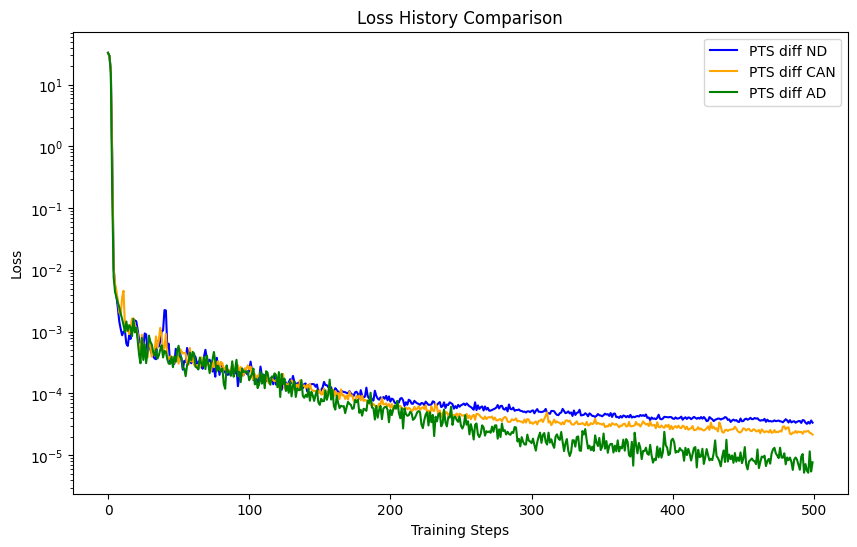

In [ ]:
loss_hist_ad = hist_ad.get("loss", [])
loss_hist_nd = hist_nd.get("loss", [])
loss_hist_can = hist_can.get("loss", [])
time_hist = 
#plot to compare loss history
plt.figure(figsize=(10, 6))
plt.plot(loss_hist_nd, label='PTS diff ND', color='blue')
plt.plot(loss_hist_can, label='PTS diff CAN', color='orange')
plt.plot(loss_hist_ad, label='PTS diff AD', color='green')
plt.title("Loss History Comparison")
plt.xlabel("Training Steps")
plt.ylabel("Loss")
plt.yscale("log")
plt.legend()

In [9]:
import os
import jax
import jax.numpy as jnp
import numpy as np


def export_to_vtk(
    model,
    filename="porous_convection.vtk",
    Nx=128,
    Ny=128,
    save_dir="outputs/vtk_plots",
):
  """Xuất các trường nghiệm (u, v, p, T, |U|) từ mô hình PINN sang định dạng VTK để mở trong ParaView."""
  os.makedirs(save_dir, exist_ok=True)
  filepath = os.path.join(save_dir, filename)

  # 1. Tạo lưới tọa độ đều trên miền [0, L] x [0, H]
  x_lin = np.linspace(0.0, float(model.L), Nx)
  y_lin = np.linspace(0.0, float(model.H), Ny)
  dx = float(model.L) / (Nx - 1)
  dy = float(model.H) / (Ny - 1)

  # Lưu ý: VTK structured points quét theo thứ tự X tăng trước, sau đó tới Y, Z
  X, Y = np.meshgrid(x_lin, y_lin, indexing="xy")
  x_flat = jnp.array(X.ravel())
  y_flat = jnp.array(Y.ravel())

  # 2. Đánh giá trường nghiệm qua mạng nơ-ron
  eval_fn = jax.vmap(model.neural_net, in_axes=(None, 0, 0))
  u_pred, v_pred, p_pred, T_pred = eval_fn(model.state.params, x_flat, y_flat)

  u_np = np.asarray(u_pred, dtype=np.float32)
  v_np = np.asarray(v_pred, dtype=np.float32)
  p_np = np.asarray(p_pred, dtype=np.float32)
  T_np = np.asarray(T_pred, dtype=np.float32)
  vel_mag = np.sqrt(u_np**2 + v_np**2)
  w_np = np.zeros_like(u_np)  # Vận tốc thành phần z = 0 cho bài toán 2D

  num_points = Nx * Ny

  # 3. Ghi file theo chuẩn Legacy VTK ASCII
  with open(filepath, "w") as f:
    f.write("# vtk DataFile Version 3.0\n")
    f.write("Porous Natural Convection PINN Solution\n")
    f.write("ASCII\n")
    f.write("DATASET STRUCTURED_POINTS\n")
    f.write(f"DIMENSIONS {Nx} {Ny} 1\n")
    f.write("ORIGIN 0.0 0.0 0.0\n")
    f.write(f"SPACING {dx:.6e} {dy:.6e} 1.0\n")
    f.write(f"POINT_DATA {num_points}\n")

    # Trường nhiệt độ T
    f.write("SCALARS Temperature float 1\n")
    f.write("LOOKUP_TABLE default\n")
    np.savetxt(f, T_np, fmt="%.6e")

    # Trường áp suất p
    f.write("SCALARS Pressure float 1\n")
    f.write("LOOKUP_TABLE default\n")
    np.savetxt(f, p_np, fmt="%.6e")

    # Độ lớn vận tốc |u|
    f.write("SCALARS Velocity_Magnitude float 1\n")
    f.write("LOOKUP_TABLE default\n")
    np.savetxt(f, vel_mag, fmt="%.6e")

    # Vector vận tốc U = (u, v, 0) để vẽ Streamlines / Glyph trong ParaView
    f.write("VECTORS Velocity float\n")
    velocity_vectors = np.column_stack([u_np, v_np, w_np])
    np.savetxt(f, velocity_vectors, fmt="%.6e %.6e %.6e")

  print(f"-> Đã xuất thành công file VTK tại: {filepath}")
  return filepath

In [10]:
import numpy as np
import matplotlib.pyplot as plt

def plot_ffv_pinn_style(X, Y, u_pred, v_pred, T_pred, title_prefix="PINN", save_path=None):
    """
    Hàm xuất 4 biểu đồ Contour (u, v, V_mag, T) trên cùng một hàng ngang 
    chuẩn format bài báo FFV-PINN.
    """
    V_mag = np.sqrt(u_pred**2 + v_pred**2)

    fig, axes = plt.subplots(1, 4, figsize=(22, 4.5))
    
    data_list = [u_pred, v_pred, V_mag, T_pred]
    titles = [f"{title_prefix} $u$", f"{title_prefix} $v$", f"{title_prefix} $V$", f"{title_prefix} $T$"]

    cmap = 'jet' 
    
    for i, ax in enumerate(axes):
        data = data_list[i]
        title = titles[i]

        cf = ax.contourf(X, Y, data, levels=100, cmap=cmap, extend='both')
        
        cbar = fig.colorbar(cf, ax=ax, fraction=0.046, pad=0.04)
        cbar.ax.tick_params(labelsize=11)
        
        ax.set_title(title, fontsize=15, pad=10)
        ax.set_xlabel("$x$", fontsize=13)
        ax.set_ylabel("$y$", fontsize=13)
        ax.set_aspect('equal')
        ax.set_xlim([0, 1])
        ax.set_ylim([0, 1])
    
        ax.set_xticks([0.0, 0.5, 1.0])
        ax.set_yticks([0.0, 0.2, 0.4, 0.6, 0.8, 1.0])
        ax.tick_params(axis='both', which='major', labelsize=11)

    plt.tight_layout()

    if save_path:
        plt.savefig(save_path, dpi=300, bbox_inches='tight')
        
    plt.show()

In [11]:
import copy
import gc
import glob
import os
import numpy as np
import jax.numpy as jnp
from jaxpi.checkpointing import create_checkpoint_manager, restore_checkpoint
import utils
from nc_porous import models

OUTPUT_DIR = "./results_vtk_plots"
os.makedirs(OUTPUT_DIR, exist_ok=True)

benchmark_expectations = {
    1e6: {"u_max": 64.63, "y_u": 0.850, "v_max": 219.36, "x_v": 0.0379, "Nu": 8.8},
}

def compute_nusselt_number_lsa(model, params, config, Ny=201):
    """
    Tính Nu chuẩn xác theo nguyên lý LSA của FVM:
    Nu(y) = (T_wall - T(h/2, y)) / (h/2)
    """
    h = config.fvm_setup.h_stencil
    x_half = h / 2.0
    y_lin = np.linspace(0.0, 1.0, Ny)
    
    # Đánh giá nhiệt độ tại đúng tâm ô FVM đầu tiên (x = h/2)
    x_in = np.full_like(y_lin, x_half)
    _, _, _, T_half = jax.vmap(model.u_net, in_axes=(None, 0, 0))(params, x_half * np.ones_like(y_lin), y_lin)
    T_half = np.array(T_half)
    
    # T_wall theo bài toán đối lưu tự nhiên là 1.0
    Nu_local = (1.0 - T_half) / x_half
    Nu_avg = np.trapezoid(Nu_local, x=y_lin)
    
    print("\n" + "="*50)
    print(f"Calculated Average Nusselt Number (Nu_avg): {Nu_avg:.4f}")
    print(f"Maximum Local Nusselt Number (Nu_max): {np.max(Nu_local):.4f}")
    print("="*50)
    
    plt.figure(figsize=(5, 6))
    plt.plot(Nu_local, y_lin, 'r-', linewidth=2)
    plt.title("Local Nusselt Number along Hot Wall ($x=0$)")
    plt.xlabel("$Nu$")
    plt.ylabel("$y$")
    plt.grid(True, linestyle='--', alpha=0.6)
    plt.show()
    
    return Nu_avg, Nu_local

def evaluate_saved_experiments(experiments_list, step_to_load=150000, output_dir=OUTPUT_DIR):
    print("="*60)
    print("BẮT ĐẦU QUÁ TRÌNH TRÍCH XUẤT, VẼ ẢNH VÀ ĐÁNH GIÁ")
    print("="*60)
    
    log_path = os.path.join(output_dir, "ket_qua_benchmark.txt")
    with open(log_path, "a", encoding="utf-8") as log_file:
        log_file.write(f"\n\n--- ĐÁNH GIÁ MỚI (Step: {step_to_load}) ---\n")

    for exp in experiments_list:
        exp_name = exp["name"]
        Ra_val = exp["Ra"]
        shared_size = exp["SHARED_SIZE"]
        branch_size = exp["BRANCH_SIZE"]
        
        print(f"\nĐang xử lý model: {exp_name}")
        
        sub_config = copy.deepcopy(base_line_ffv.get_config())
        sub_config.wandb.name = sub_config.wandb.name + "/" + exp_name
        sub_config.arch.shared_dim = shared_size
        sub_config.arch.branch_dim = branch_size
        sub_config.physics.Ra = Ra_val 
        
        lr = create_lr_schedule(sub_config.optim)
        tx = create_optimizer(sub_config.optim, lr)
        arch = create_arch(sub_config.arch)
        empty_state = create_train_state(sub_config, tx, arch)
        
        pattern = f"/home/sonndt/Projects/FFV_PINN/nc_porous/*/{exp_name}/ckpt"
        matches = glob.glob(pattern)
        
        if not matches:
            print(f" LỖI: Không tìm thấy folder checkpoint cho '{exp_name}' theo pattern: {pattern}")
            continue
            
        ckpt_path = matches[0]
        ckpt_mngr = create_checkpoint_manager(sub_config.saving, ckpt_path)
        
        restored_state = None
        restored_model = None
        
        try:
            restored_state = restore_checkpoint(ckpt_mngr, empty_state, step=step_to_load)
            restored_model = models.LidCavityPorous_fvm(sub_config, lr, tx, arch, restored_state, lb, ub)
            
            X, Y, x_lin, y_lin, u_pred, v_pred, p_pred, T_pred = generate_prediction_grid(
                model=restored_model, 
                params=restored_state.params,
                config=sub_config, 
                Nx=201, Ny=201
            )

            img_save_path = os.path.join(output_dir, f"cavity_results_{exp_name}.png")
            plot_ffv_pinn_style(
                X=X, Y=Y, 
                u_pred=u_pred, v_pred=v_pred, T_pred=T_pred, 
                title_prefix=f"Scale-PINN ({exp_name})", 
                save_path=img_save_path
            )
            mid_x_idx = len(x_lin) // 2  
            mid_y_idx = len(y_lin) // 2  
            u_mid_y = u_pred[:, mid_x_idx]
            idx_u = np.argmax(u_mid_y)
            u_max_val = u_mid_y[idx_u]  
            y_of_umax = y_lin[idx_u]

            v_mid_x = v_pred[mid_y_idx, :]
            idx_v = np.argmax(v_mid_x)
            v_max_val = v_mid_x[idx_v]
            x_of_vmax = x_lin[idx_v]
                        
            Nu_avg, Nu_local = compute_nusselt_number_lsa(model=restored_model, params=restored_state.params, config=sub_config, Ny=201)
            
            exp_vals = benchmark_expectations[Ra_val]
            
            report = (
                f"\n{'='*60}\n"
                f"KẾT QUẢ ĐỐI SÁNH - BẢNG 2 LIU ET AL. | MODEL: {exp_name}\n"    
                f"{'='*60}\n"
                f"1. Vận tốc ngang u_max  : {u_max_val:.4f} (Kỳ vọng: ~{exp_vals['u_max']})\n"
                f"   => Xảy ra tại tọa độ y : {y_of_umax:.4f} (Kỳ vọng: ~{exp_vals['y_u']})\n"
                f"{'-'*60}\n"
                f"2. Vận tốc dọc v_max    : {v_max_val:.4f} (Kỳ vọng: ~{exp_vals['v_max']})\n"
                f"   => Xảy ra tại tọa độ x : {x_of_vmax:.4f} (Kỳ vọng: ~{exp_vals['x_v']})\n"
                f"{'-'*60}\n"
                f"3. Số Nusselt trung bình: {Nu_avg:.4f} (Kỳ vọng: ~{exp_vals['Nu']})\n"
                f"{'='*60}\n"
            )
            print(report)
            with open(log_path, "a", encoding="utf-8") as log_file:
                log_file.write(report)

            print(f"✔ Đã xử lý xong toàn bộ cho: {exp_name} (Kết quả đã lưu vào {output_dir})")
            
        except Exception as e:
            print(f"GẶP LỖI CHI TIẾT TẠI {exp_name}: {e}")
            
        finally:
            for var_name in ["empty_state", "restored_state", "restored_model"]:
                if var_name in locals() and locals()[var_name] is not None:
                    del locals()[var_name]
            if "sub_config" in locals():
                del sub_config
            gc.collect()

experiments_to_evaluate = [
    {"name": "soap_test", "Ra": 1e6, "SHARED_SIZE": 128, "BRANCH_SIZE": 64},
]

evaluate_saved_experiments(experiments_to_evaluate, step_to_load=40000, output_dir=OUTPUT_DIR)

BẮT ĐẦU QUÁ TRÌNH TRÍCH XUẤT, VẼ ẢNH VÀ ĐÁNH GIÁ

Đang xử lý model: soap_test


TypeError: ModifiedMlp.__init__() got an unexpected keyword argument 'branch_dim'